In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("MH AI Vision")
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("CPU:", tf.config.list_physical_devices("CPU"))

MH AI Vision
TensorFlow: 2.22.0-rc0
NumPy: 2.5.2
CPU: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("===== MH AI VISION =====")
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Available devices:", tf.config.list_physical_devices())

===== MH AI VISION =====
TensorFlow: 2.22.0-rc0
NumPy: 2.5.2
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [4]:

import os
import urllib.request

# Dataset directory
DATA_DIR = "dataset/mnist"
os.makedirs(DATA_DIR, exist_ok=True)

base_url = "https://raw.githubusercontent.com/fgnt/mnist/master/"

files = [
    "train-images-idx3-ubyte.gz",
    "train-labels-idx1-ubyte.gz",
    "t10k-images-idx3-ubyte.gz",
    "t10k-labels-idx1-ubyte.gz"
]

for filename in files:
    path = os.path.join(DATA_DIR, filename)

    if not os.path.exists(path):
        url = base_url + filename
        print("Downloading:", filename)
        urllib.request.urlretrieve(url, path)
        print("Downloaded successfully!")
    else:
        print("Already exists:", filename)

print("\nMNIST download process finished.")


Downloading: train-images-idx3-ubyte.gz
Downloaded successfully!
Downloading: train-labels-idx1-ubyte.gz
Downloaded successfully!
Downloading: t10k-images-idx3-ubyte.gz
Downloaded successfully!
Downloading: t10k-labels-idx1-ubyte.gz
Downloaded successfully!

MNIST download process finished.


In [6]:

import gzip
import numpy as np
import os

def load_images(filename):
    path = os.path.join(DATA_DIR, filename)

    with gzip.open(path, "rb") as f:
        data = f.read()

    return np.frombuffer(data, dtype=np.uint8, offset=16).reshape(-1, 28, 28)

def load_labels(filename):
    path = os.path.join(DATA_DIR, filename)

    with gzip.open(path, "rb") as f:
        data = f.read()

    return np.frombuffer(data, dtype=np.uint8, offset=8)

x_train = load_images("train-images-idx3-ubyte.gz")
y_train = load_labels("train-labels-idx1-ubyte.gz")

x_test = load_images("t10k-images-idx3-ubyte.gz")
y_test = load_labels("t10k-labels-idx1-ubyte.gz")

print("Training:", x_train.shape, y_train.shape)
print("Testing:", x_test.shape, y_test.shape)


Training: (60000, 28, 28) (60000,)
Testing: (10000, 28, 28) (10000,)


In [7]:

import gzip
import numpy as np
import os

def load_images(filename):
    path = os.path.join(DATA_DIR, filename)

    with gzip.open(path, "rb") as f:
        data = f.read()

    return np.frombuffer(
        data, dtype=np.uint8, offset=16
    ).reshape(-1, 28, 28)


def load_labels(filename):
    path = os.path.join(DATA_DIR, filename)

    with gzip.open(path, "rb") as f:
        data = f.read()

    return np.frombuffer(
        data, dtype=np.uint8, offset=8
    )


# Load training and testing data
x_train = load_images("train-images-idx3-ubyte.gz")
y_train = load_labels("train-labels-idx1-ubyte.gz")

x_test = load_images("t10k-images-idx3-ubyte.gz")
y_test = load_labels("t10k-labels-idx1-ubyte.gz")

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)


Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


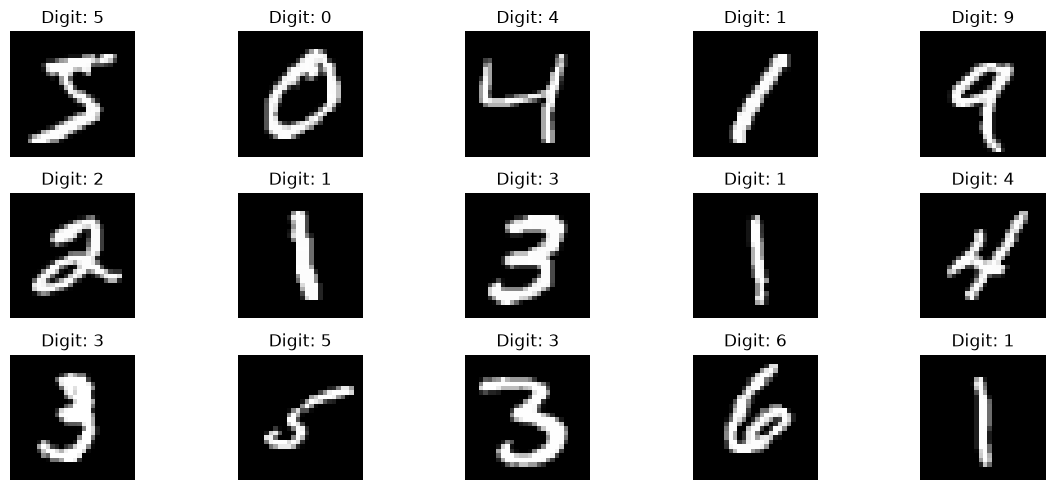

In [8]:

plt.figure(figsize=(12, 5))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:

# Normalize image pixels

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension for CNN
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

print("Minimum pixel:", x_train.min())
print("Maximum pixel:", x_train.max())


Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)
Minimum pixel: 0.0
Maximum pixel: 1.0


In [10]:

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu"
    ),

    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu"
    ),

    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MH AI Vision model is ready!")


MH AI Vision model is ready!


In [12]:

# Training configuration

EPOCHS = 5
BATCH_SIZE = 128

history = model.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    verbose=1
)


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9217 - loss: 0.2640 - val_accuracy: 0.9833 - val_loss: 0.0565
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9763 - loss: 0.0776 - val_accuracy: 0.9882 - val_loss: 0.0410
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9835 - loss: 0.0553 - val_accuracy: 0.9892 - val_loss: 0.0434
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9861 - loss: 0.0442 - val_accuracy: 0.9905 - val_loss: 0.0357
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9896 - loss: 0.0347 - val_accuracy: 0.9905 - val_loss: 0.0340


In [13]:

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9905 - loss: 0.0267
Test Loss: 0.0267
Test Accuracy: 99.05%


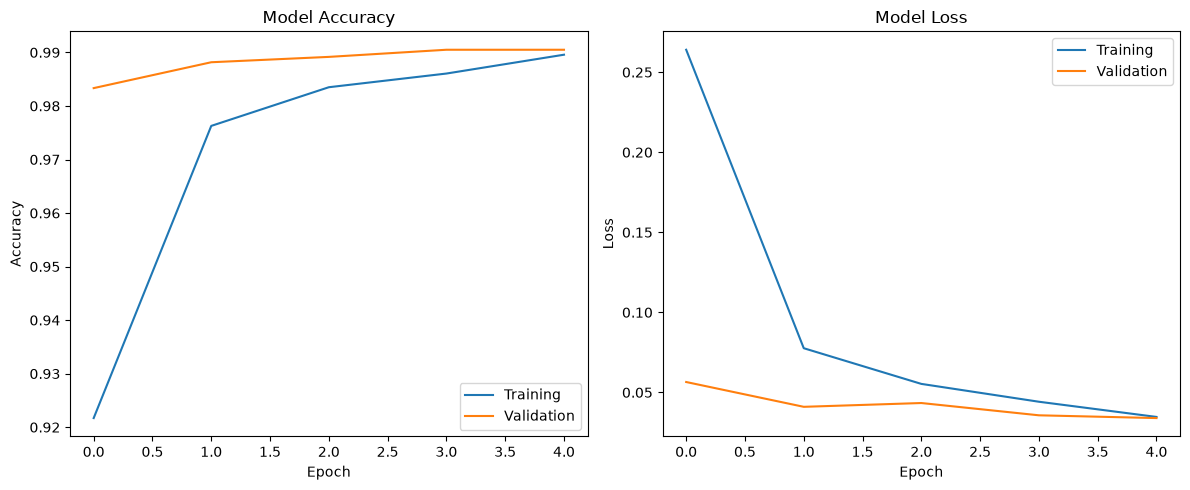

In [14]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [15]:

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("\n===== MH AI VISION RESULTS =====")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9905 - loss: 0.0267

===== MH AI VISION RESULTS =====
Test Accuracy: 99.05%
Test Loss: 0.0267


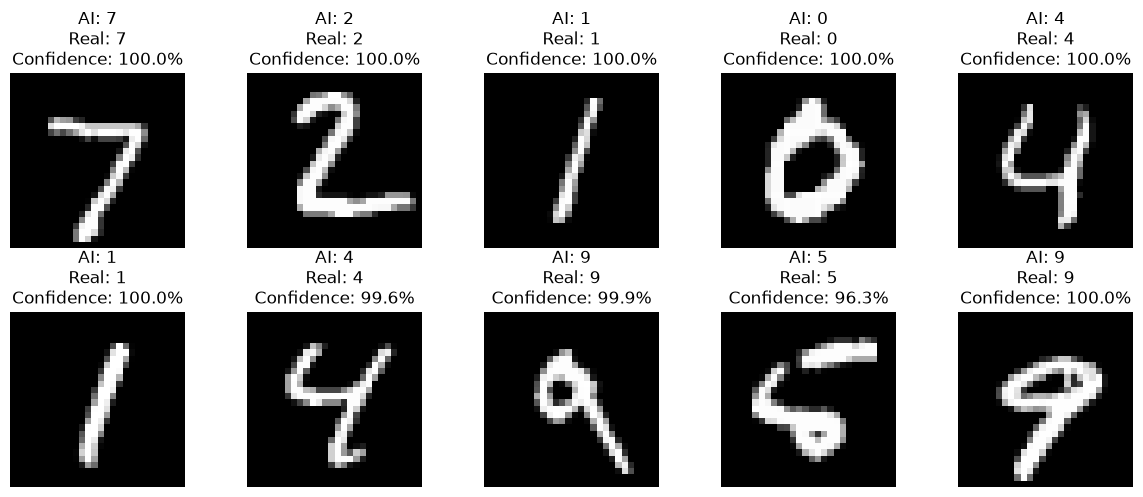

In [16]:

predictions = model.predict(x_test[:10], verbose=0)

plt.figure(figsize=(12, 5))

for i in range(10):
    predicted_digit = np.argmax(predictions[i])
    confidence = np.max(predictions[i]) * 100

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")

    plt.title(
        f"AI: {predicted_digit}\n"
        f"Real: {y_test[i]}\n"
        f"Confidence: {confidence:.1f}%"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


In [17]:

model.save("MH_AI_Vision.keras")

print("Model saved successfully!")


Model saved successfully!


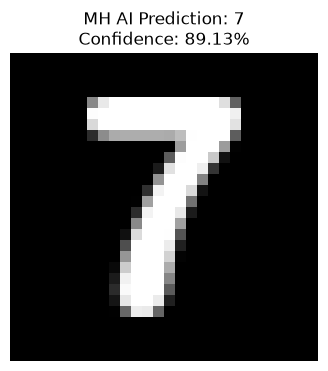

===== MH AI VISION =====
Detected Number: 7
Confidence: 89.13%


In [20]:
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

# Load image
image = Image.open("my_digit.png").convert("L")

# Convert black writing on white paper
# to white writing on black background
image = ImageOps.invert(image)

# Find the digit area
image = image.point(lambda p: 255 if p > 80 else 0)

bbox = image.getbbox()

if bbox is None:
    raise ValueError("No digit found in the image!")

image = image.crop(bbox)

# Resize while preserving proportions
image.thumbnail((20, 20))

# Put digit in the center of a 28x28 image
canvas = Image.new("L", (28, 28), 0)

x = (28 - image.width) // 2
y = (28 - image.height) // 2

canvas.paste(image, (x, y))

# Normalize image
processed_image = np.array(canvas).astype("float32") / 255.0
processed_image = processed_image.reshape(1, 28, 28, 1)

# Predict
prediction = model.predict(processed_image, verbose=0)

digit = np.argmax(prediction)
confidence = np.max(prediction) * 100

# Display result
plt.figure(figsize=(4, 4))
plt.imshow(canvas, cmap="gray")
plt.title(f"MH AI Prediction: {digit}\nConfidence: {confidence:.2f}%")
plt.axis("off")
plt.show()

print("===== MH AI VISION =====")
print("Detected Number:", digit)
print(f"Confidence: {confidence:.2f}%")

In [22]:
import os

print("Current folder:", os.getcwd())
print(os.listdir())

Current folder: c:\Users\pc\Pictures\MH_AI_VISION
['dataset', 'MH_AI_Vision.keras', 'my_digit', 'my_digit.png', 'VISION.ipynb']


In [23]:
def recognize_digit(image_path):

    image = Image.open(image_path).convert("L")
    image = ImageOps.invert(image)

    image = image.point(lambda p: 255 if p > 80 else 0)

    bbox = image.getbbox()

    if bbox is None:
        print("No digit found!")
        return

    image = image.crop(bbox)
    image.thumbnail((20, 20))

    canvas = Image.new("L", (28, 28), 0)

    x = (28 - image.width) // 2
    y = (28 - image.height) // 2

    canvas.paste(image, (x, y))

    data = np.array(canvas).astype("float32") / 255.0
    data = data.reshape(1, 28, 28, 1)

    prediction = model.predict(data, verbose=0)

    digit = np.argmax(prediction)
    confidence = np.max(prediction) * 100

    print("===== MH AI VISION =====")
    print("Detected Number:", digit)
    print(f"Confidence: {confidence:.2f}%")

    plt.imshow(canvas, cmap="gray")
    plt.title(f"Prediction: {digit}")
    plt.axis("off")
    plt.show()

===== MH AI VISION =====
Detected Number: 7
Confidence: 89.13%


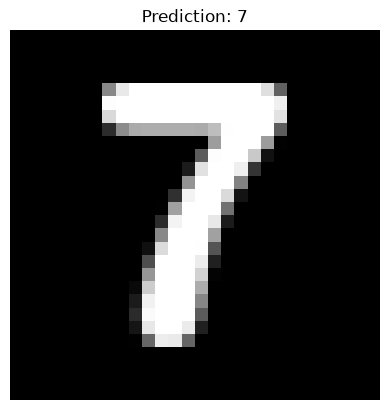

In [24]:
recognize_digit("my_digit.png")

In [25]:
from ultralytics import YOLO

# Load pretrained object detection model
yolo_model = YOLO("yolo26n.pt")

print("MH AI Vision - YOLO Model Loaded!")
print("Model task:", yolo_model.task)

MH AI Vision - YOLO Model Loaded!
Model task: detect



image 1/1 c:\Users\pc\Pictures\MH_AI_VISION\my_digit.png: 640x640 1 snowboard, 110.1ms
Speed: 7.6ms preprocess, 110.1ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\Users\pc\Pictures\MH_AI_VISION\runs\detect\predict


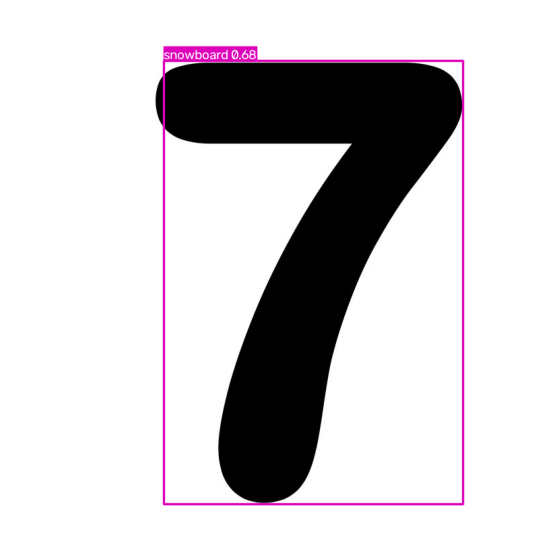

Object: snowboard | Confidence: 67.66%


In [27]:
# Detect objects in an image
results = yolo_model.predict(
    source="my_digit.png",
    conf=0.25,
    save=True
)

# Display detection results
import matplotlib.pyplot as plt

result_image = results[0].plot()

plt.figure(figsize=(10, 7))
plt.imshow(result_image[:, :, ::-1])
plt.axis("off")
plt.show()

# Print detected objects
for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    name = yolo_model.names[class_id]

    print(f"Object: {name} | Confidence: {confidence * 100:.2f}%")


image 1/1 c:\Users\pc\Pictures\MH_AI_VISION\animals.jpg: 640x448 1 dog, 144.7ms
Speed: 1.9ms preprocess, 144.7ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 448)
Results saved to C:\Users\pc\Pictures\MH_AI_VISION\runs\detect\predict


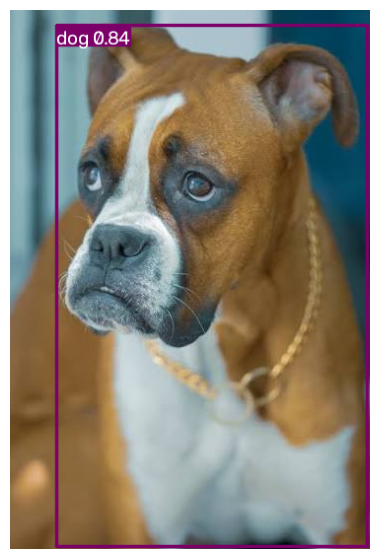

In [28]:
results = yolo_model.predict(
    source="animals.jpg",
    conf=0.25,
    save=True
)

result_image = results[0].plot()

plt.figure(figsize=(10, 7))
plt.imshow(result_image[:, :, ::-1])
plt.axis("off")
plt.show()